# Python DA Assignment 2 - Data Visualization

### 1. Loading the Dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# Load taxis dataset
df = sns.load_dataset("taxis")
# Display first 5 rows
print(df.head())


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

### 2. Handling Missing Values


In [5]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
# Numerical columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns


In [7]:
num_cols

Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='str')

In [9]:
# Categorical columns
cat_cols = df.select_dtypes(include=['object', 'string', 'category']).columns


In [12]:
print(cat_cols)

Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')


In [24]:
# Impute numerical columns with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [25]:
# Impute categorical columns with mode
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [26]:
print("Missing Values After Treatment:")
print(df.isnull().sum())

Missing Values After Treatment:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [27]:
# Remove rows with remaining critical missing values
df.dropna(inplace=True)

### 3. Visualizations using Matplotlib/Pandas

In [29]:
# Convert pickup column to datetime
df['pickup'] = pd.to_datetime(df['pickup'])

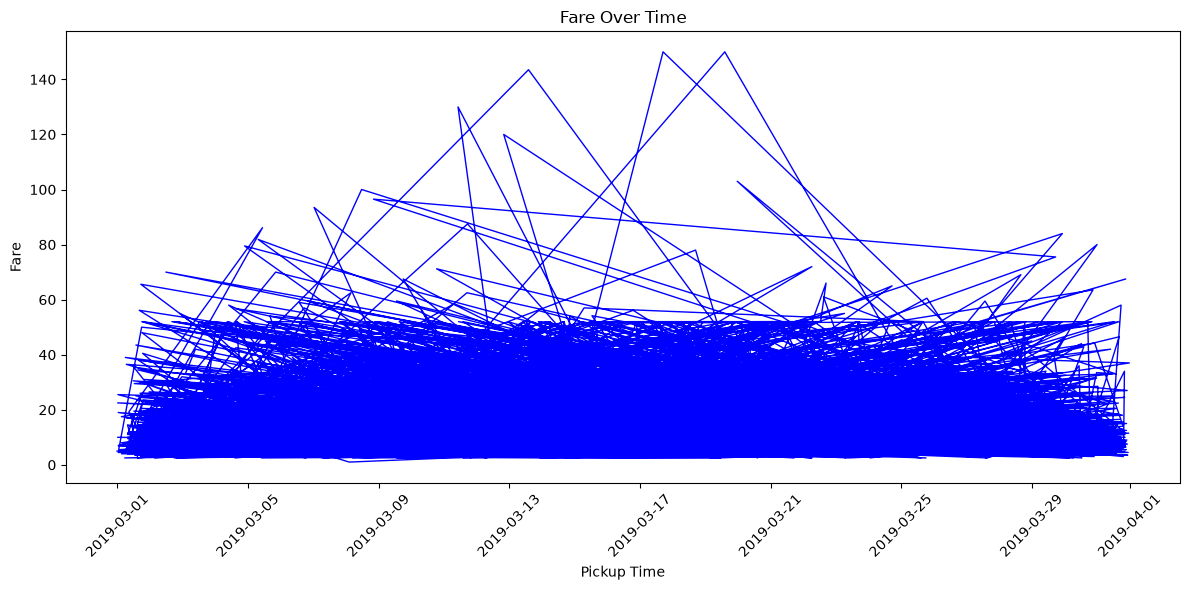

In [33]:
#  Line Chart
plt.figure(figsize=(12,6))

plt.plot(df['pickup'], df['fare'],
         color='blue',
         linewidth=1)

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

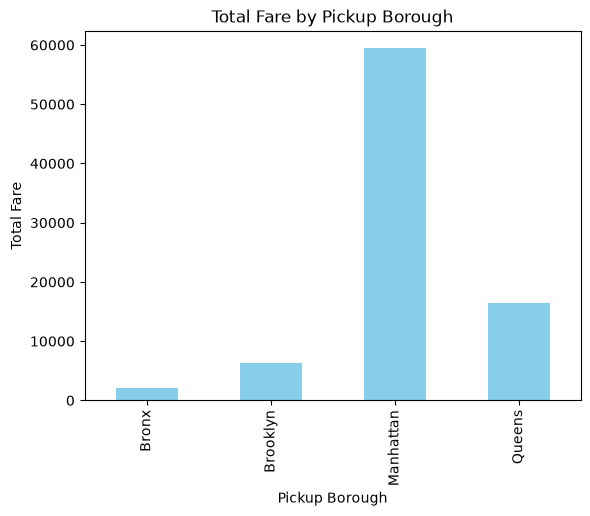

In [35]:
# Bar Chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare.plot(kind='bar', color='skyblue')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.show()

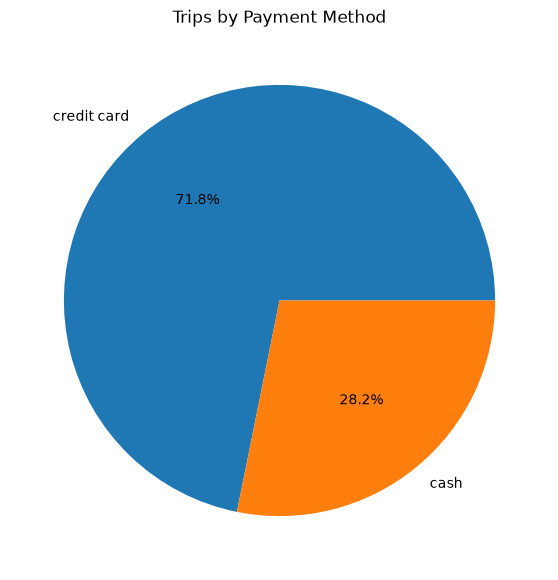

In [36]:
#  Pie Chart 
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct='%1.1f%%')

plt.title('Trips by Payment Method')
plt.show()

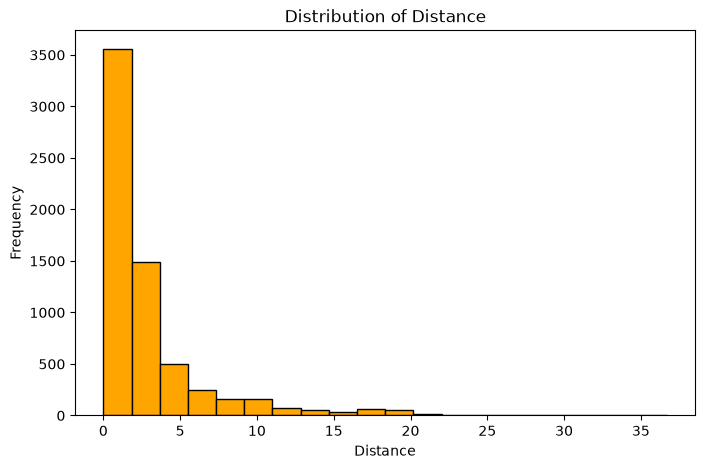

In [37]:
# Histogram 
plt.figure(figsize=(8,5))
plt.hist(df['distance'],
         bins=20,
         color='orange',
         edgecolor='black')

plt.title('Distribution of Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

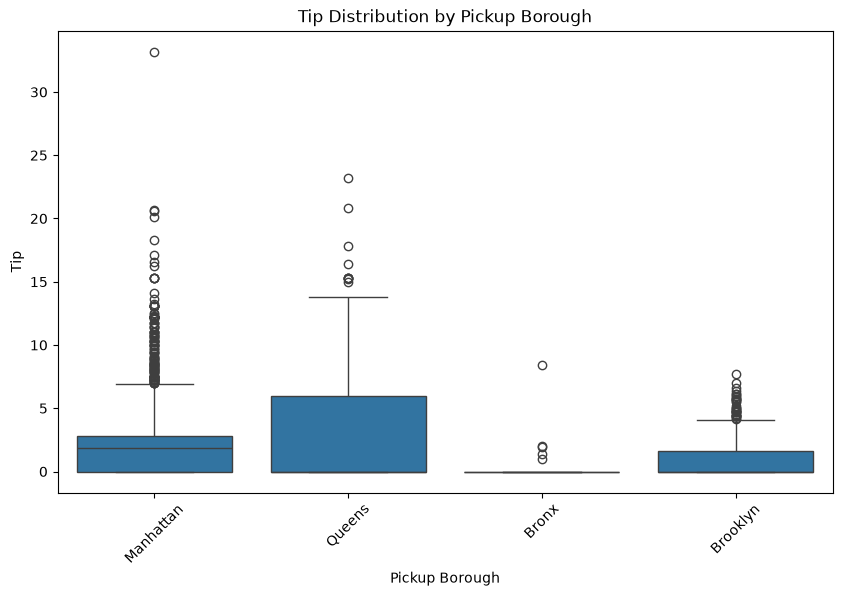

In [40]:
#  Box Plot
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip')

plt.title('Tip Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip')
plt.xticks(rotation=45)

plt.show()

### 4. Visualizations using Seaborn

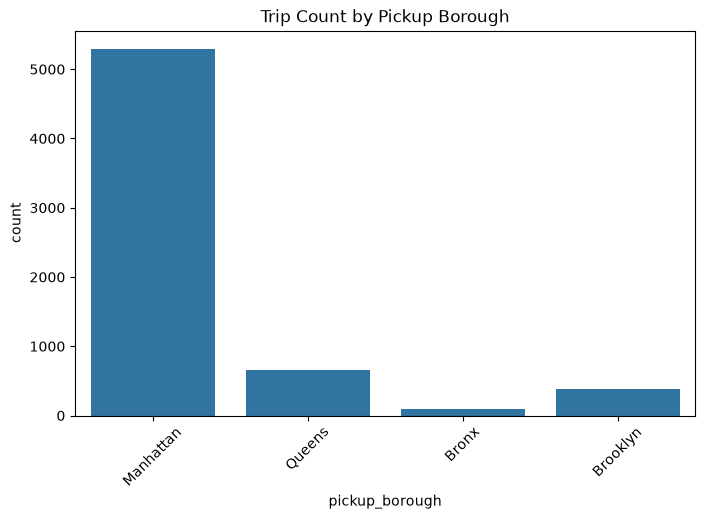

In [41]:
# Count Plot 
plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='pickup_borough')

plt.title('Trip Count by Pickup Borough')
plt.xticks(rotation=45)
plt.show()

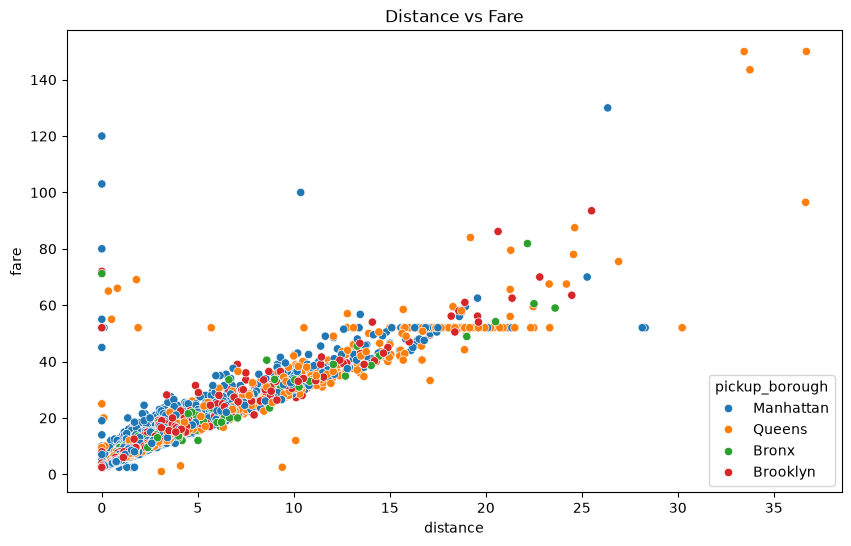

In [43]:
# Scatter Plot 
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough')

plt.title('Distance vs Fare')
plt.show()

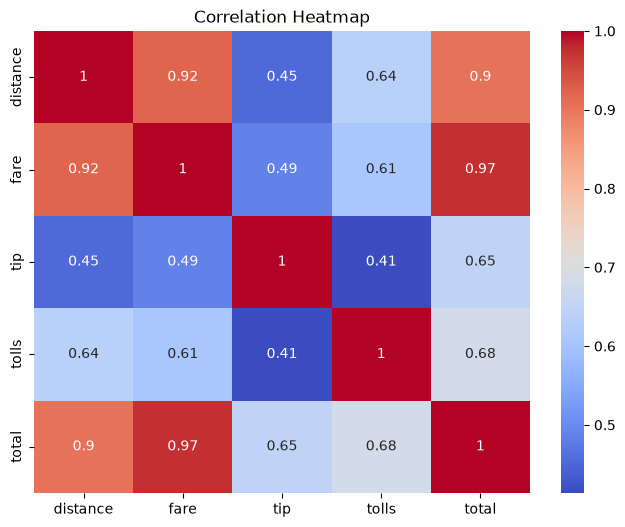

In [45]:
#  Heatmap
plt.figure(figsize=(8,6))

corr_matrix = df[
    ['distance',
     'fare',
     'tip',
     'tolls',
     'total']
].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

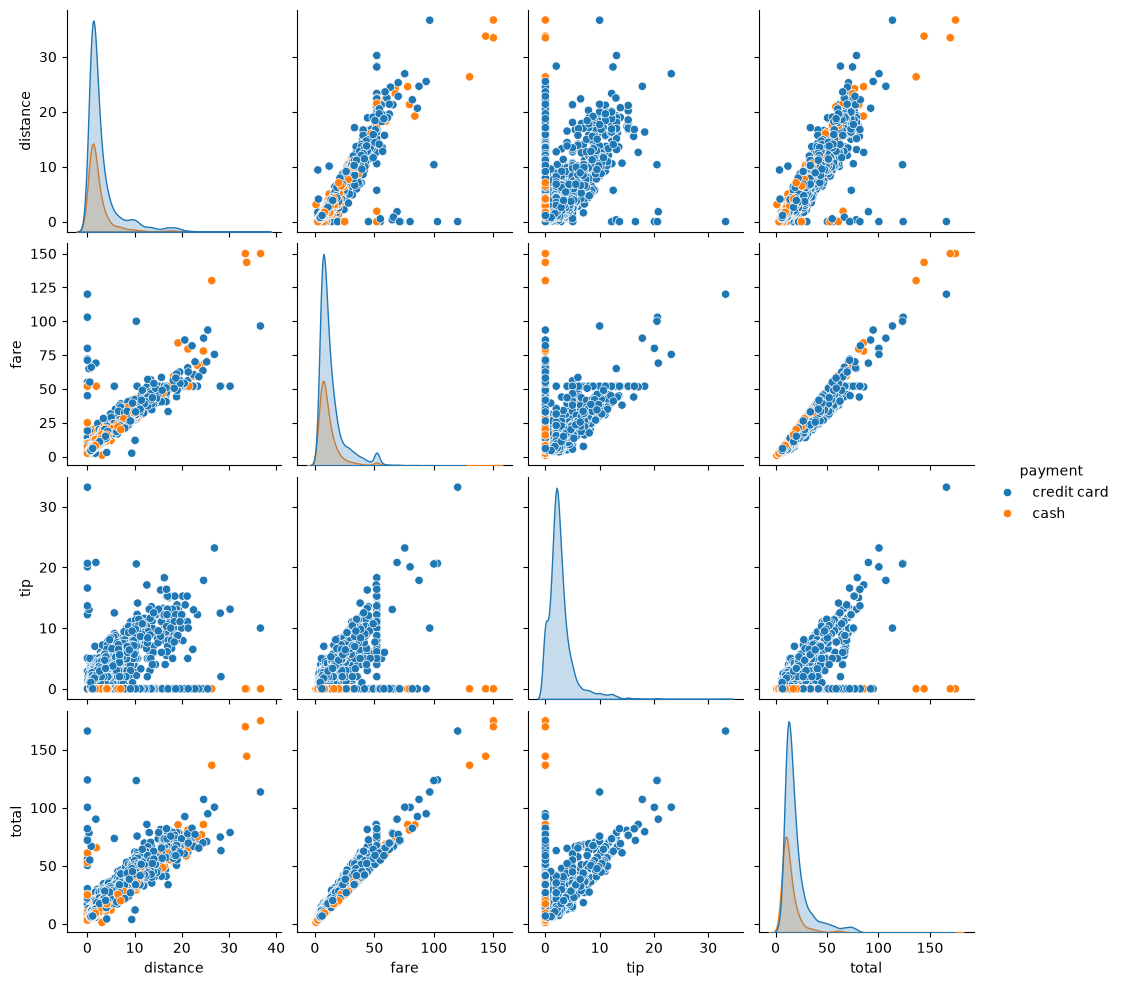

In [48]:
#  Pair Plot 
sns.pairplot(
    df,
    vars=['distance',
          'fare',
          'tip',
          'total'],
    hue='payment'
)

plt.show()

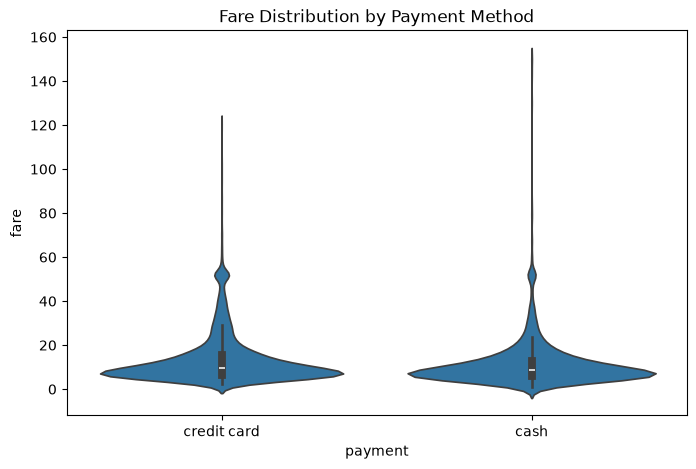

In [49]:
#  Violin Plot 
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare')

plt.title('Fare Distribution by Payment Method')

plt.show()